# FinanzIA · Análisis y justificación del modelo de IA

**Entrega final · Inteligencia Artificial**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ErickEsquivel/finazia/blob/main/notebooks/FinanzIA_analisis_modelo.ipynb)

FinanzIA es una app de finanzas personales para estudiantes y personas con ingresos variables. Cada vez que registramos un movimiento, **la IA lo clasifica** en una categoría y, con esa categoría, la app **calcula** el presupuesto, los gastos hormiga, la regla 50/30/20 y las alertas.

El cuaderno sigue el mismo orden de la sustentación:

| Parte | Contenido |
|---|---|
| **1. El problema** | Por qué es clasificación · las 7 clases y por qué esas · características y variable objetivo |
| **2. El set de datos** | Cómo se construyó · ingresos variables · PLN: de texto a números · división 70 / 10 / 20 |
| **3. Evolución de los modelos** | Versión 1 y su problema · 5 clasificadores con hiperparámetros ajustados · métricas en prueba · prueba externa · decisión |
| **4. Integración en la app** | Modelo final · cómo lo usa la app · confianza · correcciones · movimientos inusuales |
| **5. Cierre** | Respuestas al feedback del profesor · conclusiones y limitaciones |

Repositorio de la app: https://github.com/ErickEsquivel/finazia

> Corre completo en Colab en unos 3 minutos. Las semillas están fijas, así que los resultados se pueden reproducir.

In [1]:
import re, time, unicodedata, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
SEMILLA = 42
np.random.seed(SEMILLA)
print("scikit-learn", sklearn.__version__)

AZUL, NARANJA, VERDE, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#b5b3ad", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": TINTA,
                     "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
                     "axes.titleweight": "bold", "figure.dpi": 110})
PORCENTAJE = plt.matplotlib.ticker.PercentFormatter(1)

# Los datos se leen de la carpeta datos/ del repositorio (o de GitHub si estamos en Colab)
def leer(nombre):
    for ruta in [Path("../datos") / nombre, Path("datos") / nombre, Path(nombre)]:
        if ruta.exists():
            return pd.read_csv(ruta, encoding="utf-8-sig")
    return pd.read_csv("https://raw.githubusercontent.com/ErickEsquivel/finazia/main/datos/" + nombre, encoding="utf-8-sig")

df = leer("dataset_multivariable.csv")
df["fecha_hora"] = pd.to_datetime(df["fecha_hora"])
print(df.shape)
df.head()

scikit-learn 1.9.1
(700, 5)


,fecha_hora,monto,tipo_movimiento,descripcion_libre,categoria
0,2026-05-01 09:21:22,135000,Gasto,Factura de energía Enel Codensa,Vivienda y Servicios
1,2026-05-01 21:19:16,19000,Gasto,Alitas y pola con los de la U,Ocio y Entretenimiento
2,2026-05-02 08:52:07,906500,Gasto,Cuota de arriendo habitación por PSE,Vivienda y Servicios
3,2026-05-02 09:18:17,99000,Gasto,Factura plan móvil Tigo con Nequi,Vivienda y Servicios
4,2026-05-02 10:49:30,41000,Gasto,Transferencia pago fijo del mes,Vivienda y Servicios


# Parte 1 · El problema

## 1.1 ¿Por qué es un problema de clasificación?

Lo que queremos que la IA responda es: *"¿a qué categoría pertenece este movimiento?"*. La respuesta es una **etiqueta de una lista cerrada**, no un número. Eso define el tipo de problema:

| Tipo de problema | Qué predice | ¿Sirve para FinanzIA? |
|---|---|---|
| Regresión | Un número continuo (ej. cuánto voy a gastar el próximo mes) | No: la salida que necesitamos es una categoría |
| Agrupamiento (no supervisado) | Grupos que el algoritmo inventa, sin nombre | No: los grupos no coincidirían con las categorías del presupuesto |
| **Clasificación supervisada** | **Una etiqueta de una lista conocida, aprendida de ejemplos ya etiquetados** | **Sí** |

- Es **supervisado** porque cada ejemplo de entrenamiento trae la respuesta correcta (la categoría que pusimos a mano).
- Es **multiclase** porque hay 7 categorías posibles y cada movimiento pertenece a **una sola**.

**La IA clasifica; el presupuesto se calcula.** La IA solo pone la categoría. El presupuesto, el porcentaje usado, la regla 50/30/20 y la proyección de gastos hormiga son **sumas y porcentajes** sobre esas categorías:

```
"almuerzo corrientazo"  $14.000  Gasto  martes 12:40
        │
        ▼
  [ IA: KNN ]  ──►  Alimentación (confianza 92 %) + los vecinos que explican por qué
        │
        ▼
  [ Reglas ]   ──►  Alimentación lleva 78 % del límite → aviso "cerca del límite"
```

## 1.2 Las 7 clases y por qué esas

Escogimos las clases a partir de **lo que la app tiene que calcular**: cada una alimenta una función concreta.

| Clase | Qué incluye | Por qué existe | Bloque 50/30/20 |
|---|---|---|---|
| **Alimentación** | Mercado y comidas principales | Es el gasto necesario más frecuente | Necesidades |
| **Transporte** | Pasajes, apps de viaje, gasolina, parqueadero | Gasto diario de todo estudiante o trabajador | Necesidades |
| **Vivienda y Servicios** | Arriendo, servicios, internet, celular, aseo y arreglos de la casa | Gastos fijos del mes | Necesidades |
| **Salud y Educación** | Droguería, citas, gimnasio, universidad, cursos, papelería | Inversión en uno mismo, no se debe recortar | Necesidades |
| **Ocio y Entretenimiento** | Salidas, suscripciones, juegos, comidas de plan con amigos | Gasto de gusto, el primero a recortar | Deseos |
| **Gastos Hormiga** | Compras pequeñas, impulsivas y repetidas (menos de ~$11.000) | Es la función estrella de la app: lo que no se ve y suma mucho al mes | Deseos |
| **Ingresos** | Toda entrada de dinero | Sin ingresos no hay saldo ni presupuesto real | (base del cálculo) |

**Criterios de etiquetado manual** (para los casos que podían caer en dos clases):

1. **El tipo manda:** un *Ingreso* siempre es *Ingresos*; un *Gasto* nunca lo es. La app lo hace cumplir.
2. **Comida necesaria vs. comida de plan:** el almuerzo del día o el mercado es *Alimentación*; la hamburguesa con amigos o la pizza por Rappi es *Ocio*.
3. **Pequeño e impulsivo = hormiga:** un antojo por debajo de ~$11.000 es *Gasto Hormiga*; una comida principal es *Alimentación*.
4. **Hogar vs. persona:** el jabón en polvo de la casa es *Vivienda*; la crema dental o la peluquería es cuidado personal (*Salud y Educación*).
5. **Gimnasio** cuenta como salud, no como ocio.
6. **El medio de pago no define la clase:** "con Nequi", "por PSE" o "en efectivo" no cambian la categoría.

In [2]:
regla_tipo = ((df.tipo_movimiento == "Ingreso") == (df.categoria == "Ingresos")).mean()
max_hormiga = df.loc[df.categoria == "Gastos Hormiga", "monto"].max()
min_alimentacion = df.loc[df.categoria == "Alimentación", "monto"].min()
print(f"Regla 1 (Ingreso <=> Ingresos) se cumple en el {regla_tipo:.0%} de las filas")
print(f"Regla 3: el gasto hormiga más caro es ${max_hormiga:,.0f}; la alimentación más barata, ${min_alimentacion:,.0f}")

Regla 1 (Ingreso <=> Ingresos) se cumple en el 100% de las filas
Regla 3: el gasto hormiga más caro es $10,900; la alimentación más barata, $11,300


## 1.3 Características (X) y variable objetivo (y)

**Variable objetivo (dependiente), `y`:** `categoria`, con las 7 clases.

**Características (independientes), `X`:** lo que el usuario escribe al registrar un movimiento.

| Característica | Tipo | Cómo se convierte en número | Qué aporta |
|---|---|---|---|
| `descripcion_libre` | Texto | TF-IDF de palabras y pares de palabras (sección 2.3) | La pista principal: "tinto", "arriendo", "Uber" |
| `tipo_movimiento` | Categórica (Gasto / Ingreso) | One-hot: 0 o 1 | Separa ingresos de gastos |
| `monto` | Numérica | Estandarización (media 0, desviación 1) | Desempata textos ambiguos: "compra pequeña" vs. "compras del mes" |
| `fecha_hora` → `hora`, `dia_semana`, `dia_mes`, `es_fin_de_semana` | Numéricas | Estandarización | Contexto: la rumba es de noche y de fin de semana; el arriendo, a principio de mes |

*Fin de semana = viernes, sábado y domingo*, porque en nuestros datos el viernes en la noche ya se comporta como fin de semana. Es la misma definición que usa la app.

In [3]:
def extraer_variables_temporales(X):
    # Convierte fecha_hora en 4 números. La app usa exactamente esta función.
    columna = X.iloc[:, 0] if isinstance(X, pd.DataFrame) else pd.Series(np.asarray(X).ravel())
    fechas = pd.to_datetime(columna)
    dia_semana = fechas.dt.dayofweek  # 0 = lunes ... 6 = domingo
    return pd.DataFrame({
        "hora": fechas.dt.hour.to_numpy(),
        "dia_semana": dia_semana.to_numpy(),
        "dia_mes": fechas.dt.day.to_numpy(),
        "es_fin_de_semana": (dia_semana >= 4).astype(int).to_numpy(),
    })

COLUMNAS_X = ["fecha_hora", "monto", "tipo_movimiento", "descripcion_libre"]
X = df[COLUMNAS_X]
y = df["categoria"]
extraer_variables_temporales(X[["fecha_hora"]]).head()

,hora,dia_semana,dia_mes,es_fin_de_semana
0,9,4,1,1
1,21,4,1,1
2,8,5,2,1
3,9,5,2,1
4,10,5,2,1


# Parte 2 · El set de datos

## 2.1 Cómo construimos los datos

No existen datos públicos de gastos de estudiantes colombianos con descripciones en español informal, y no queríamos usar extractos bancarios reales de personas. Por eso construimos un **dataset sintético controlado**, en 4 pasos:

1. **Frases base por clase:** escribimos entre 16 y 20 descripciones típicas de cada clase, como las escribiría un estudiante ("recarga tarjeta TuLlave Transmilenio", "tinto en Juan Valdez").
2. **Variantes de escritura:** a cada frase le agregamos lo que la gente escribe de verdad: medio de pago ("con Nequi", "por PSE", "en efectivo", "pago rápido"), "hoy", mayúsculas o sin tildes.
3. **Monto, fecha y hora realistas:** cada clase tiene su rango (un tinto entre $1.500 y $11.000; el arriendo, cientos de miles), con fechas de mayo a octubre de 2026.
4. **Etiquetado y revisión:** cada fila lleva su clase según los criterios de la sección 1.2, y verificamos las reglas con código.

Resultado: **700 movimientos, 100 por clase** (balanceado, para que ninguna clase domine el aprendizaje).

Como varias filas comparten la misma frase base, calculamos esa **frase base** quitando el medio de pago, "hoy", las tildes y las mayúsculas. La vamos a necesitar para dividir los datos sin hacer trampa (sección 2.4).

In [4]:
SUFIJOS = ["con nequi", "por pse", "pago rapido", "en efectivo", "hoy"]

def frase_base(texto):
    # 'Recarga tarjeta SITP por PSE' y 'recarga tarjeta sitp hoy' -> 'recarga tarjeta sitp'
    t = unicodedata.normalize("NFKD", str(texto).lower()).encode("ascii", "ignore").decode()
    t = re.sub(r"\s+", " ", t).strip()
    cambio = True
    while cambio:
        cambio = False
        for s in SUFIJOS:
            if t.endswith(" " + s):
                t, cambio = t[: -len(s) - 1].strip(), True
    return t

df["frase_base"] = df.descripcion_libre.map(frase_base)
grupos = df["frase_base"]

resumen = df.groupby("categoria").agg(filas=("monto", "size"),
                                      descripciones_distintas=("descripcion_libre", "nunique"),
                                      frases_base=("frase_base", "nunique"),
                                      monto_min=("monto", "min"), monto_mediana=("monto", "median"),
                                      monto_max=("monto", "max"))
print("Descripciones distintas:", df.descripcion_libre.nunique(), "| Frases base:", df.frase_base.nunique())
print("Frases base repetidas en más de una clase:", (df.groupby("frase_base").categoria.nunique() > 1).sum())
resumen.style.format({"monto_min": "${:,.0f}", "monto_mediana": "${:,.0f}", "monto_max": "${:,.0f}"})

Descripciones distintas: 529 | Frases base: 126
Frases base repetidas en más de una clase: 0


,filas,descripciones_distintas,frases_base,monto_min,monto_mediana,monto_max
categoria,,,,,,
Alimentación,100,80,19,"$11,300","$78,000","$278,500"
Gastos Hormiga,100,77,20,"$1,500","$6,400","$10,900"
Ingresos,100,77,16,"$26,000","$652,750","$1,585,000"
Ocio y Entretenimiento,100,69,20,"$17,000","$75,500","$125,000"
Salud y Educación,100,73,16,"$3,900","$67,000","$1,171,000"
Transporte,100,74,19,"$3,700","$25,000","$93,000"
Vivienda y Servicios,100,79,16,"$36,500","$95,000","$1,181,000"


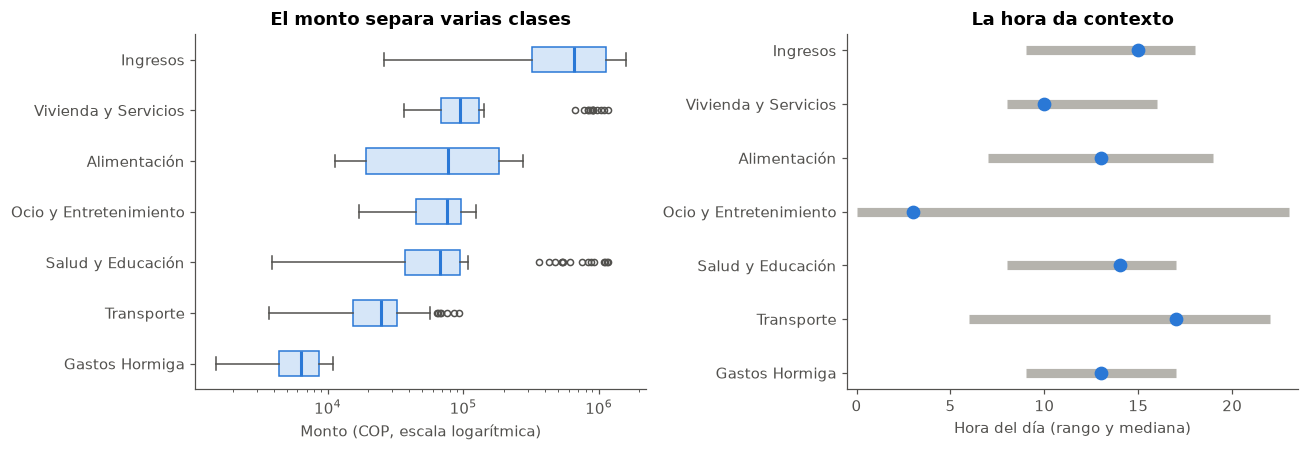

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
orden = resumen.sort_values("monto_mediana").index
ejes[0].boxplot([df.loc[df.categoria == c, "monto"] for c in orden], vert=False, widths=.5,
                patch_artist=True, boxprops=dict(facecolor="#d6e6f8", edgecolor=AZUL),
                medianprops=dict(color=AZUL, linewidth=2), whiskerprops=dict(color=TINTA), capprops=dict(color=TINTA),
                flierprops=dict(markeredgecolor=TINTA, markersize=4))
ejes[0].set_yticks(range(1, 8), orden); ejes[0].set_xscale("log")
ejes[0].set_xlabel("Monto (COP, escala logarítmica)"); ejes[0].set_title("El monto separa varias clases")

horas = df.assign(hora=df.fecha_hora.dt.hour).groupby("categoria").hora.agg(["min", "median", "max"]).loc[orden]
ejes[1].hlines(range(7), horas["min"], horas["max"], color=GRIS, linewidth=6)
ejes[1].plot(horas["median"], range(7), "o", color=AZUL, markersize=8)
ejes[1].set_yticks(range(7), orden); ejes[1].set_xlabel("Hora del día (rango y mediana)")
ejes[1].set_title("La hora da contexto"); ejes[1].set_xlim(-0.5, 23.5)
plt.tight_layout(); plt.show()

## 2.2 ¿Cómo simulamos los ingresos variables?

Nuestro usuario no tiene un sueldo fijo. Por eso los 100 ingresos mezclan **16 tipos de ingreso**:

- **Fijos o casi fijos:** quincena, mesada, apoyo mensual de los papás (días 15, 16, 28 a 30).
- **Variables:** freelance, clases particulares, monitoría, soporte técnico, ventas en Marketplace, bonos, devoluciones de la "vaca".
- **Montos** desde $26.000 hasta $1.585.000, para que el modelo no asuma que "ingreso = sueldo grande".

En la app esto se refleja en que el presupuesto se calcula sobre lo que **realmente** entró en el mes.

In [6]:
ing = df[df.categoria == "Ingresos"]
print(f"Montos de ingresos: mínimo ${ing.monto.min():,.0f} | mediana ${ing.monto.median():,.0f} | máximo ${ing.monto.max():,.0f}")
print("Días del mes más frecuentes:", ing.fecha_hora.dt.day.value_counts().head(6).to_dict())
ing.groupby("frase_base").monto.agg(veces="count", mediana="median").sort_values("veces", ascending=False)

Montos de ingresos: mínimo $26,000 | mediana $652,750 | máximo $1,585,000
Días del mes más frecuentes: {30: 21, 15: 15, 5: 14, 16: 12, 28: 11, 10: 10}


,veces,mediana
frase_base,,
pago de quincena nomina,12,500000.0
venta de articulo usado por marketplace,10,664750.0
pago monitoria academica universidad,9,519500.0
clases particulares de calculo y fisica,8,757250.0
me pagaron plata que me debian por daviplata,8,731750.0
bono o comision extra de trabajo,8,616750.0
devolucion de la vaca por nequi,8,613250.0
mesada semanal transferencia bancolombia,6,621000.0
transferencia recibida en nequi,5,718000.0


## 2.3 PLN: cómo pasamos de texto a números

Un modelo no entiende palabras, solo números. El procesamiento de la descripción tiene 4 pasos:

1. **Normalización:** todo a minúsculas.
2. **Tokenización:** se parte el texto en palabras ("tinto", "con", "nequi").
3. **N-gramas (1, 2):** además de cada palabra, se toman los **pares de palabras seguidas** ("tinto con", "con nequi"). Así "pago arriendo" no es lo mismo que "pago" + "arriendo" sueltos en cualquier orden.
4. **Vectorización:** cada palabra o par se vuelve una columna. Probamos dos formas:
   - **Bolsa de palabras (BoW):** cuenta cuántas veces aparece cada palabra.
   - **TF-IDF:** cuenta cuántas veces aparece (TF) y lo multiplica por qué tan **rara** es la palabra en todo el dataset (IDF). Una palabra que aparece en todas partes ("pago", "con") pesa poco; una que distingue ("tinto", "arriendo") pesa mucho. Además, cada fila queda normalizada (longitud 1), así una descripción larga no "pesa" más que una corta.

$$\text{TF-IDF}(t, d) = \text{tf}(t, d) \times \left(\ln \frac{1 + n}{1 + \text{df}(t)} + 1\right)$$

Ejemplo con cuatro descripciones:

In [7]:
ejemplo = ["tinto con nequi", "tinto y empanada", "pago arriendo con nequi", "almuerzo con nequi"]
bow = CountVectorizer().fit(ejemplo)
tfidf = TfidfVectorizer().fit(ejemplo)
print("Bolsa de palabras (conteos):")
display(pd.DataFrame(bow.transform(ejemplo).toarray(), columns=bow.get_feature_names_out(), index=ejemplo))
print("TF-IDF (las palabras raras pesan más; cada fila tiene longitud 1):")
display(pd.DataFrame(tfidf.transform(ejemplo).toarray(), columns=tfidf.get_feature_names_out(), index=ejemplo).round(2))

Bolsa de palabras (conteos):


,almuerzo,arriendo,con,empanada,nequi,pago,tinto
tinto con nequi,0,0,1,0,1,0,1
tinto y empanada,0,0,0,1,0,0,1
pago arriendo con nequi,0,1,1,0,1,1,0
almuerzo con nequi,1,0,1,0,1,0,0


TF-IDF (las palabras raras pesan más; cada fila tiene longitud 1):


,almuerzo,arriendo,con,empanada,nequi,pago,tinto
tinto con nequi,0.00,0.0,0.53,0.00,0.53,0.0,0.66
tinto y empanada,0.00,0.0,0.00,0.79,0.00,0.0,0.62
pago arriendo con nequi,0.00,0.6,0.38,0.00,0.38,0.6,0.00
almuerzo con nequi,0.74,0.0,0.47,0.00,0.47,0.0,0.00


Fíjense en la primera fila: con bolsa de palabras "tinto", "con" y "nequi" valen lo mismo (1). Con TF-IDF, **"tinto" pesa más** que "con" y "nequi", porque "con" y "nequi" aparecen en 3 de las 4 descripciones y casi no ayudan a distinguir. En la tercera fila, "pago" y "arriendo" (que solo aparecen ahí) son las que más pesan. TF-IDF le da más peso a lo que **distingue** una descripción de las demás.

**Las demás características** también se vuelven números:
- `tipo_movimiento` → **one-hot** (Gasto = 0, Ingreso = 1).
- `monto` y las 4 variables de tiempo → **estandarización** (a cada valor se le resta la media y se divide por la desviación), para que $1.000.000 no aplaste a "hora = 14".
- Cada bloque se multiplica por un **peso** (`transformer_weights`) que dice cuánto cuenta en la distancia entre movimientos. Los pesos se ajustan en la sección 3.3.

Al final, cada movimiento es un vector de unas 1.100 columnas (casi todas de texto). Elegimos entre BoW y TF-IDF con datos de ajuste en la sección 3.3.

## 2.4 División de los datos: 70 % entrenamiento · 10 % ajuste · 20 % prueba

| Conjunto | % | Para qué |
|---|---|---|
| **Entrenamiento** | 70 % | El modelo aprende de estos ejemplos |
| **Ajuste (validación)** | 10 % | Escoger hiperparámetros y representación del texto, sin tocar la prueba |
| **Prueba** | 20 % | Medir el resultado final **una sola vez**, al terminar |

**La división es agrupada por frase base y estratificada por clase:** todas las variantes de una misma frase quedan en el mismo conjunto, y cada conjunto tiene todas las clases. ¿Por qué agrupada? Lo explica la sección 3.2: con una división aleatoria, la prueba se llena de frases "hermanas" de las de entrenamiento y el resultado sale inflado.

**El 10 % de ajuste se rota.** Un solo 10 % son unas 70 filas y unas 11 frases base: muy poco para escoger hiperparámetros con confianza. Por eso, sin tocar el 20 % de prueba, repetimos la división 70/10 **8 veces** dentro del 80 % restante, rotando qué parte es el ajuste, y promediamos. Cada configuración se evalúa 8 veces, siempre entrenando con 70 % y ajustando con 10 %.

In [8]:
bloques = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEMILLA).split(X, y, grupos))
idx_prueba = np.concatenate([bloques[0][1], bloques[1][1]])                      # 2 de 10 bloques = 20 %
idx_desarrollo = np.setdiff1d(np.arange(len(X)), idx_prueba)                    # 80 % = entrenamiento + ajuste
RONDAS_AJUSTE = [(np.concatenate([bloques[j][1] for j in range(2, 10) if j != i]), bloques[i][1])
                 for i in range(2, 10)]                                          # 8 rondas de 70 % / 10 %

X_dev, y_dev = X.iloc[idx_desarrollo], y.iloc[idx_desarrollo]
X_prueba, y_prueba = X.iloc[idx_prueba], y.iloc[idx_prueba]

n = len(X)
print(f"Prueba: {len(idx_prueba)} filas ({len(idx_prueba)/n:.0%}), {grupos.iloc[idx_prueba].nunique()} frases base nunca vistas")
for k, (tr, va) in enumerate(RONDAS_AJUSTE[:3], 1):
    print(f"Ronda {k}: entrenamiento {len(tr)} ({len(tr)/n:.0%}) · ajuste {len(va)} ({len(va)/n:.0%})")
print("...")
print("¿Alguna frase base de la prueba aparece en entrenamiento o ajuste?",
      bool(set(grupos.iloc[idx_prueba]) & set(grupos.iloc[idx_desarrollo])))
print("Filas de prueba por clase:", y_prueba.value_counts().to_dict())

Prueba: 140 filas (20%), 25 frases base nunca vistas
Ronda 1: entrenamiento 493 (70%) · ajuste 67 (10%)
Ronda 2: entrenamiento 491 (70%) · ajuste 69 (10%)
Ronda 3: entrenamiento 490 (70%) · ajuste 70 (10%)
...
¿Alguna frase base de la prueba aparece en entrenamiento o ajuste? False
Filas de prueba por clase: {'Ingresos': 23, 'Ocio y Entretenimiento': 21, 'Alimentación': 20, 'Salud y Educación': 20, 'Vivienda y Servicios': 19, 'Gastos Hormiga': 19, 'Transporte': 18}


# Parte 3 · Evolución de los modelos

## 3.1 Versión 1: la primera comparación

Nuestra primera comparación (script `entrenamiento_algoritmos_v1.py`, en esta carpeta) usó una división **aleatoria** 80/20 (560 para entrenar, 140 para probar), TF-IDF (1-2 gramas), los pesos por bloque que pusimos a ojo (texto 3.0, tipo 1.5, monto 0.6, tiempo 0.25) y hiperparámetros fijos (KNN con K = 5). Precisión, recall y F1 son *weighted*, y la columna CV es la accuracy promedio de una validación cruzada de 5 particiones. Naive Bayes usa `MinMaxScaler` porque no acepta números negativos. Abajo la reproducimos con el mismo código.

In [9]:
PESOS_V1 = {"texto": 3.0, "tipo": 1.5, "numero": 0.6, "tiempo": 0.25}

def construir_preprocesador(pesos, para_naive_bayes=False, vectorizador="tfidf", ngramas=(1, 2)):
    # Misma estructura que el .pkl de la app: tiempo, monto ('numero'), tipo y texto
    Escalador = MinMaxScaler if para_naive_bayes else StandardScaler
    Vectorizador = TfidfVectorizer if vectorizador == "tfidf" else CountVectorizer
    return ColumnTransformer(
        transformers=[
            ("tiempo", Pipeline([("extractor", FunctionTransformer(extraer_variables_temporales)),
                                 ("escalador_tiempo", Escalador())]), ["fecha_hora"]),
            ("numero", Escalador(), ["monto"]),
            ("tipo", OneHotEncoder(drop="if_binary"), ["tipo_movimiento"]),
            ("texto", Vectorizador(ngram_range=ngramas), "descripcion_libre"),
        ],
        transformer_weights=pesos,
    )

def crear(nombre, pesos, **hp):
    clasificadores = {
        "KNN": lambda: KNeighborsClassifier(**{"n_neighbors": 5, "weights": "distance", "metric": "euclidean", **hp}),
        "Random Forest": lambda: RandomForestClassifier(random_state=SEMILLA, **hp),
        "SVM": lambda: SVC(**{"kernel": "linear", **hp}),
        "Naive Bayes": lambda: MultinomialNB(**hp),
        "Reg. Logística": lambda: LogisticRegression(max_iter=2000, **hp),
    }
    return Pipeline([("preprocesador", construir_preprocesador(pesos, nombre == "Naive Bayes")),
                     ("clasificador", clasificadores[nombre]())])

MODELOS = ["KNN", "Random Forest", "SVM", "Naive Bayes", "Reg. Logística"]

X_tr_al, X_te_al, y_tr_al, y_te_al = train_test_split(X, y, test_size=0.20, random_state=SEMILLA, stratify=y)

# ---- Versión 1 exactamente como en entrenamiento_algoritmos_v1.py ----
from sklearn.model_selection import cross_val_score
v1_df = df.copy()
v1_df["hora"] = v1_df.fecha_hora.dt.hour
v1_df["dia_mes"] = v1_df.fecha_hora.dt.day
v1_df["dia_semana"] = v1_df.fecha_hora.dt.weekday
v1_df["es_fin_semana"] = (v1_df["dia_semana"] >= 5).astype(int)   # en la v1, fin de semana = sábado y domingo
X_v1 = v1_df[["descripcion_libre", "tipo_movimiento", "monto", "hora", "dia_mes", "dia_semana", "es_fin_semana"]]
Xv1_tr, Xv1_te, yv1_tr, yv1_te = train_test_split(X_v1, y, test_size=0.20, random_state=42, stratify=y)

def prep_v1(Escalador):
    return ColumnTransformer([
        ("texto", TfidfVectorizer(ngram_range=(1, 2)), "descripcion_libre"),
        ("tipo", OneHotEncoder(handle_unknown="ignore"), ["tipo_movimiento"]),
        ("monto", Escalador(), ["monto"]),
        ("tiempo", Escalador(), ["hora", "dia_mes", "dia_semana", "es_fin_semana"])],
        transformer_weights={"texto": 3.0, "tipo": 1.5, "monto": 0.6, "tiempo": 0.25})

modelos_v1 = {
    "KNN": Pipeline([("prep", prep_v1(StandardScaler)), ("clf", KNeighborsClassifier(n_neighbors=5, weights="distance", metric="euclidean"))]),
    "Random Forest": Pipeline([("prep", prep_v1(StandardScaler)), ("clf", RandomForestClassifier(n_estimators=100, max_depth=None, max_features="sqrt", criterion="gini", random_state=42))]),
    "SVM": Pipeline([("prep", prep_v1(StandardScaler)), ("clf", SVC(C=1.0, kernel="linear", random_state=42))]),
    "Naive Bayes": Pipeline([("prep", prep_v1(MinMaxScaler)), ("clf", MultinomialNB(alpha=1.0))]),
    "Reg. Logística": Pipeline([("prep", prep_v1(StandardScaler)), ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=42))]),
}
filas = []
for nombre, modelo in modelos_v1.items():
    t0 = time.perf_counter(); modelo.fit(Xv1_tr, yv1_tr); t_train = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); pred = modelo.predict(Xv1_te); t_pred = (time.perf_counter() - t0) * 1000
    filas.append({"Algoritmo": nombre,
                  "Accuracy": accuracy_score(yv1_te, pred),
                  "Precision": precision_score(yv1_te, pred, average="weighted"),
                  "Recall": recall_score(yv1_te, pred, average="weighted"),
                  "F1-Score": f1_score(yv1_te, pred, average="weighted"),
                  "CV 5-Fold": cross_val_score(modelo, X_v1, y, cv=5, scoring="accuracy").mean(),
                  "Tiempo Train (ms)": t_train, "Tiempo Pred (ms)": t_pred})
tabla_v1 = pd.DataFrame(filas).set_index("Algoritmo")
print("Tabla comparativa de la versión 1 (los tiempos cambian según el computador)")
tabla_v1.style.format({c: "{:.2%}" for c in ["Accuracy", "Precision", "Recall", "F1-Score", "CV 5-Fold"]}
                      | {"Tiempo Train (ms)": "{:.2f}", "Tiempo Pred (ms)": "{:.2f}"})

Tabla comparativa de la versión 1 (los tiempos cambian según el computador)


,Accuracy,Precision,Recall,F1-Score,CV 5-Fold,Tiempo Train (ms),Tiempo Pred (ms)
Algoritmo,,,,,,,
KNN,96.43%,96.94%,96.43%,96.40%,98.29%,19.65,10.51
Random Forest,95.71%,96.01%,95.71%,95.55%,98.43%,230.44,16.41
SVM,97.14%,97.62%,97.14%,97.11%,99.14%,61.86,13.84
Naive Bayes,97.86%,98.14%,97.86%,97.85%,98.86%,17.82,7.12
Reg. Logística,97.14%,97.62%,97.14%,97.11%,99.00%,41.86,7.21


Todos pasaban del 95 % (y del 98 % en validación cruzada) y la diferencia entre el mejor y KNN era de 2 errores en 140. Parecía que cualquier modelo servía. Antes de elegir nos preguntamos: **¿por qué todos aciertan casi todo?**

## 3.2 El problema que encontramos: fuga de información

Imaginen un profesor que hace un taller con 100 preguntas y luego pone un examen con 20 de esas mismas preguntas, cambiando un poco la redacción. Todos sacan 5, pero eso no prueba que entendieron.

Con la división aleatoria pasa lo mismo: "Recarga tarjeta SITP **por PSE**" queda en entrenamiento y "Recarga tarjeta SITP **hoy**" en prueba.

In [10]:
bases_train = set(grupos.loc[X_tr_al.index])
print(f"Filas de prueba (división aleatoria) cuya frase base ya estaba en entrenamiento: {grupos.loc[X_te_al.index].isin(bases_train).mean():.0%}")
print(f"Filas de prueba con el texto EXACTO ya visto en entrenamiento: {df.loc[X_te_al.index, 'descripcion_libre'].isin(set(df.loc[X_tr_al.index, 'descripcion_libre'])).mean():.0%}")

Filas de prueba (división aleatoria) cuya frase base ya estaba en entrenamiento: 91%
Filas de prueba con el texto EXACTO ya visto en entrenamiento: 38%


**9 de cada 10** movimientos de prueba tenían una frase hermana en el entrenamiento: ese 96-98 % medía **memoria**, no capacidad de generalizar. Por eso en la versión 2 pasamos a la división **70 / 10 / 20 agrupada** de la sección 2.4, ajustamos hiperparámetros y elegimos el modelo con datos que nunca había visto.

## 3.3 Versión 2: ajuste con el 10 % de ajuste

Todo en esta sección usa **solo** las 8 rondas de entrenamiento (70 %) / ajuste (10 %). La prueba (20 %) no se toca. La métrica para escoger es el **F1 macro** en ajuste: promedia el F1 de las 7 clases por igual, así ninguna clase fácil tapa a una difícil.

### a) Representación del texto: BoW vs. TF-IDF

In [11]:
def f1_ajuste(fabricar):
    # Promedio del F1 macro en las 8 rondas de ajuste (entrena con 70 %, evalúa en 10 %)
    puntajes = []
    for tr, va in RONDAS_AJUSTE:
        modelo = fabricar().fit(X.iloc[tr], y.iloc[tr])
        puntajes.append(f1_score(y.iloc[va], modelo.predict(X.iloc[va]), average="macro"))
    return np.mean(puntajes)

PESOS_BASE = {"texto": 3.0, "tipo": 1.5, "numero": 1.0, "tiempo": 0.5}
filas = []
for vec, ng, nombre in [("bow", (1, 1), "Bolsa de palabras, 1-gramas"), ("bow", (1, 2), "Bolsa de palabras, 1-2 gramas"),
                        ("tfidf", (1, 1), "TF-IDF, 1-gramas"), ("tfidf", (1, 2), "TF-IDF, 1-2 gramas")]:
    fab = lambda: Pipeline([("preprocesador", construir_preprocesador(PESOS_BASE, vectorizador=vec, ngramas=ng)),
                            ("clasificador", KNeighborsClassifier(5, weights="distance"))])
    filas.append({"Representación": nombre, "F1 macro en ajuste (KNN)": f1_ajuste(fab)})
pd.DataFrame(filas).set_index("Representación").style.format("{:.1%}").highlight_max(color="#d6e6f8")

,F1 macro en ajuste (KNN)
Representación,
"Bolsa de palabras, 1-gramas",30.8%
"Bolsa de palabras, 1-2 gramas",25.3%
"TF-IDF, 1-gramas",46.8%
"TF-IDF, 1-2 gramas",47.5%


**TF-IDF con 1-2 gramas gana por mucho.** Con bolsa de palabras, las palabras comunes ("pago", "con", "nequi") pesan igual que las que distinguen, y además las descripciones largas quedan "más lejos" de todo por tener más conteos. TF-IDF corrige las dos cosas.

### b) Hiperparámetros de cada clasificador

Para cada modelo probamos una grilla pequeña de los hiperparámetros que **más cambian su comportamiento**, y nos quedamos con el de mayor F1 macro en ajuste. Todos usan la misma representación (TF-IDF 1-2 gramas, mismas variables).

| Modelo | Hiperparámetro | Qué controla | Valores probados |
|---|---|---|---|
| **KNN** | `n_neighbors` (K) | Cuántos vecinos votan. Poco K = sensible al ruido; mucho K = mezcla clases | 3, 5, 7, 9, 11 |
| | `weights` | `distance`: los vecinos más cercanos pesan más (una corrección casi idéntica decide) | distance |
| | Pesos de monto y tiempo | Cuánto cuentan el monto y la hora frente al texto en la distancia | monto 0.6 / 1 / 2 / 3 · tiempo 0.25 / 0.5 / 1 |
| **Random Forest** | `n_estimators` | Número de árboles: más árboles, voto más estable | 100, 300 |
| | `max_depth` | Profundidad máxima: limita el sobreajuste | sin límite, 10 |
| | `min_samples_leaf` | Mínimo de ejemplos por hoja: evita reglas para un solo dato | 1, 2 |
| **SVM** | `kernel` | Frontera lineal o curva (RBF) | lineal, RBF |
| | `C` | Cuánto castiga los errores vs. qué tan ancho deja el margen | 0.1, 1, 10 |
| **Naive Bayes** | `alpha` | Suavizado de Laplace: probabilidad mínima para palabras no vistas en una clase | 0.01, 0.1, 0.5, 1 |
| **Reg. Logística** | `C` | Inverso de la regularización: C grande = menos castigo a pesos grandes | 0.1, 1, 10, 100 |

Para **KNN** agregamos un segundo criterio, porque la app lo necesita: después de **una sola corrección** del usuario, el modelo debe acertar la siguiente vez aunque cambien el monto y la hora. Lo medimos con 12 frases personales que no existen en el dataset (como "Pago a doña Rosa" = Alimentación), cada una probada en 3 variaciones (36 pruebas). Con la grilla escogemos los **pesos** de monto y tiempo (los de mejor F1 en ajuste que además aprenden de las correcciones) y dejamos **K = 5**, el valor del modelo del equipo: con pocos datos K = 3 aprende un poco más de una sola corrección, pero a medida que crezcan los datos de cada usuario un K mayor es más estable frente al ruido.

In [12]:
FRASES_PERSONALES = [  # (descripción, monto, tipo, clase que asigna el usuario, hora)
    ("Pago a doña Rosa", 12000, "Gasto", "Alimentación", 13),
    ("Transferencia a Camilo", 450000, "Gasto", "Vivienda y Servicios", 10),
    ("Pago al profe Andrés", 80000, "Gasto", "Salud y Educación", 17),
    ("Plata para el Chino", 8000, "Gasto", "Gastos Hormiga", 15),
    ("Pago a don Jaime", 5000, "Gasto", "Transporte", 7),
    ("Pago de la tía Marta", 300000, "Ingreso", "Ingresos", 10),
    ("Cuota del parche", 60000, "Gasto", "Ocio y Entretenimiento", 21),
    ("Pago a Luisa", 250000, "Gasto", "Vivienda y Servicios", 9),
    ("Vaca donde Pipe", 35000, "Gasto", "Ocio y Entretenimiento", 20),
    ("Pago donde Mono", 9000, "Gasto", "Gastos Hormiga", 16),
    ("Pago a la señora del almuerzo", 13000, "Gasto", "Alimentación", 12),
    ("Pago al tutor de inglés", 70000, "Gasto", "Salud y Educación", 18),
]
VARIACIONES = [(1.3, +2, "2026-11-28"), (0.6, -3, "2026-11-04"), (2.0, +4, "2026-11-22")]  # otro monto, hora y día

def movimiento(desc, monto, tipo, hora, fecha="2026-11-11"):
    return pd.DataFrame([{"fecha_hora": pd.Timestamp(f"{fecha} {min(max(hora, 0), 23):02d}:00"),
                          "monto": monto, "tipo_movimiento": tipo, "descripcion_libre": desc}])

CORREGIDOS = pd.concat([movimiento(d, m, t, h) for d, m, t, c, h in FRASES_PERSONALES], ignore_index=True)
ETIQUETAS_CORR = pd.Series([c for d, m, t, c, h in FRASES_PERSONALES])
SIGUIENTE_VEZ = pd.concat([movimiento(d, round(m * f, -2), t, h + dh, fecha)
                           for d, m, t, c, h in FRASES_PERSONALES for f, dh, fecha in VARIACIONES], ignore_index=True)
ESPERADO = np.array([c for d, m, t, c, h in FRASES_PERSONALES for _ in VARIACIONES])

def aprende_con_una_correccion(fabricar):
    # Entrena con el 80 % de desarrollo + las 12 correcciones; cuenta aciertos en las 36 pruebas
    modelo = fabricar().fit(pd.concat([X_dev, CORREGIDOS], ignore_index=True),
                            pd.concat([y_dev, ETIQUETAS_CORR], ignore_index=True))
    return int((modelo.predict(SIGUIENTE_VEZ) == ESPERADO).sum())

filas = []
for k in [3, 5, 7, 9, 11]:
    for w_monto in [0.6, 1.0, 2.0, 3.0]:
        for w_tiempo in [0.25, 0.5, 1.0]:
            pesos = {"texto": 3.0, "tipo": 1.5, "numero": w_monto, "tiempo": w_tiempo}
            fab = lambda: crear("KNN", pesos, n_neighbors=k)
            filas.append({"K": k, "peso monto": w_monto, "peso tiempo": w_tiempo,
                          "F1 ajuste": f1_ajuste(fab), "Aprende con 1 corrección (de 36)": aprende_con_una_correccion(fab)})
grilla_knn = pd.DataFrame(filas)
candidatas = grilla_knn[grilla_knn["Aprende con 1 corrección (de 36)"] == 36].sort_values("F1 ajuste", ascending=False)
pesos_elegidos = candidatas.iloc[0]
# K = 5 (valor del modelo del equipo) con los pesos elegidos
elegida = grilla_knn[(grilla_knn["K"] == 5) & (grilla_knn["peso monto"] == pesos_elegidos["peso monto"])
                     & (grilla_knn["peso tiempo"] == pesos_elegidos["peso tiempo"])].iloc[0]
K_FINAL = int(elegida["K"])
PESOS_FINALES = {"texto": 3.0, "tipo": 1.5, "numero": float(elegida["peso monto"]), "tiempo": float(elegida["peso tiempo"])}
print("Mejor F1 en ajuste sin restricción:")
display(grilla_knn.sort_values("F1 ajuste", ascending=False).head(5).style.format({"F1 ajuste": "{:.1%}"}).hide(axis="index"))
print("Mejores que aprenden las 36 correcciones:")
display(candidatas.head(5).style.format({"F1 ajuste": "{:.1%}"}).hide(axis="index"))
print(f"Elegida: K = {K_FINAL}, pesos = {PESOS_FINALES}")

Mejor F1 en ajuste sin restricción:


K,peso monto,peso tiempo,F1 ajuste,Aprende con 1 corrección (de 36)
7,3.000000,1.000000,55.5%,25
9,3.000000,0.500000,55.3%,25
11,3.000000,0.500000,55.3%,23
7,2.000000,1.000000,55.0%,27
3,3.000000,1.000000,54.8%,28


Mejores que aprenden las 36 correcciones:


K,peso monto,peso tiempo,F1 ajuste,Aprende con 1 corrección (de 36)
3,2.000000,0.500000,51.0%,36
3,2.000000,0.250000,47.9%,36
3,1.000000,0.500000,47.6%,36
3,0.600000,0.500000,46.1%,36
5,1.000000,0.250000,43.7%,36


Elegida: K = 5, pesos = {'texto': 3.0, 'tipo': 1.5, 'numero': 2.0, 'tiempo': 0.5}


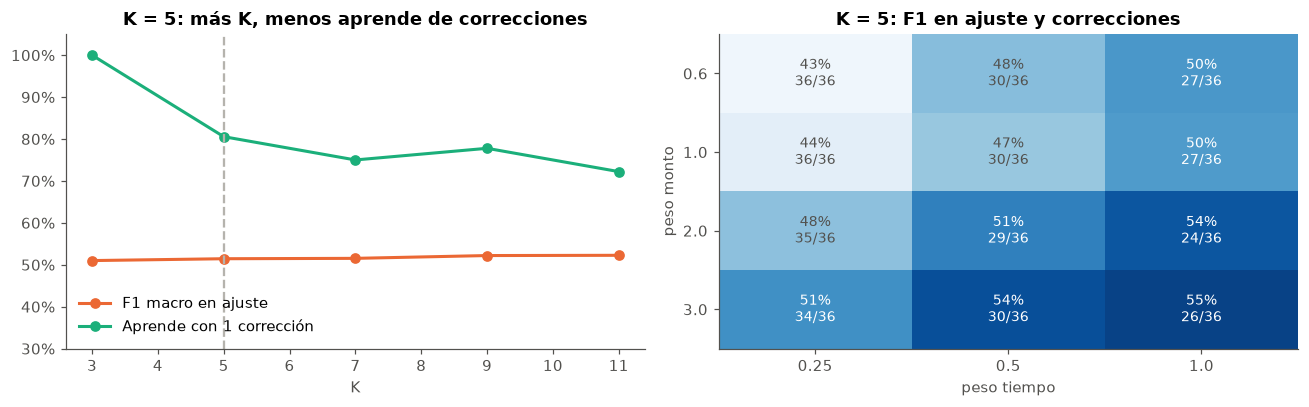

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
por_k = grilla_knn[(grilla_knn["peso monto"] == PESOS_FINALES["numero"]) & (grilla_knn["peso tiempo"] == PESOS_FINALES["tiempo"])]
ejes[0].plot(por_k["K"], por_k["F1 ajuste"], "-o", color=NARANJA, linewidth=2, label="F1 macro en ajuste")
ejes[0].plot(por_k["K"], por_k["Aprende con 1 corrección (de 36)"] / 36, "-o", color=VERDE, linewidth=2, label="Aprende con 1 corrección")
ejes[0].axvline(K_FINAL, color=GRIS, linestyle="--"); ejes[0].set_xlabel("K"); ejes[0].set_ylim(0.3, 1.05)
ejes[0].yaxis.set_major_formatter(PORCENTAJE); ejes[0].set_title(f"K = {K_FINAL}: más K, menos aprende de correcciones")
ejes[0].legend(frameon=False, loc="lower left")

mapa = grilla_knn[grilla_knn["K"] == K_FINAL].pivot(index="peso monto", columns="peso tiempo", values="F1 ajuste")
im = ejes[1].imshow(mapa.values, cmap="Blues", aspect="auto", vmin=grilla_knn["F1 ajuste"].min(), vmax=grilla_knn["F1 ajuste"].max())
ejes[1].set_xticks(range(mapa.shape[1]), mapa.columns); ejes[1].set_yticks(range(mapa.shape[0]), mapa.index)
corr = grilla_knn[grilla_knn["K"] == K_FINAL].pivot(index="peso monto", columns="peso tiempo", values="Aprende con 1 corrección (de 36)")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ejes[1].text(j, i, f"{v:.0%}\n{corr.values[i, j]}/36", ha="center", va="center", fontsize=9,
                     color="white" if v > mapa.values.mean() else TINTA)
ejes[1].set_xlabel("peso tiempo"); ejes[1].set_ylabel("peso monto")
ejes[1].set_title(f"K = {K_FINAL}: F1 en ajuste y correcciones")
plt.tight_layout(); plt.show()

In [14]:
GRILLAS = {
    "Random Forest": [dict(n_estimators=n, max_depth=d, min_samples_leaf=l) for n in [100, 300] for d in [None, 10] for l in [1, 2]],
    "SVM": [dict(kernel=k, C=c) for k in ["linear", "rbf"] for c in [0.1, 1, 10]],
    "Naive Bayes": [dict(alpha=a) for a in [0.01, 0.1, 0.5, 1.0]],
    "Reg. Logística": [dict(C=c) for c in [0.1, 1, 10, 100]],
}
HIPERPARAMETROS = {"KNN": dict(n_neighbors=K_FINAL, weights="distance", metric="euclidean")}
resumen_ajuste = [{"Modelo": "KNN", "Elegido": f"K={K_FINAL}, weights=distance, pesos monto={PESOS_FINALES['numero']}, tiempo={PESOS_FINALES['tiempo']}",
                   "F1 ajuste": elegida["F1 ajuste"]}]
for nombre, grilla in GRILLAS.items():
    resultados = [(f1_ajuste(lambda: crear(nombre, PESOS_FINALES, **hp)), hp) for hp in grilla]
    mejor_f1, mejor_hp = max(resultados, key=lambda r: r[0])
    HIPERPARAMETROS[nombre] = mejor_hp
    resumen_ajuste.append({"Modelo": nombre, "Elegido": ", ".join(f"{k}={v}" for k, v in mejor_hp.items()), "F1 ajuste": mejor_f1})
pd.DataFrame(resumen_ajuste).set_index("Modelo").style.format({"F1 ajuste": "{:.1%}"})

,Elegido,F1 ajuste
Modelo,,
KNN,"K=5, weights=distance, pesos monto=2.0, tiempo=0.5",51.4%
Random Forest,"n_estimators=300, max_depth=None, min_samples_leaf=1",69.6%
SVM,"kernel=linear, C=1",56.3%
Naive Bayes,alpha=1.0,48.2%
Reg. Logística,C=10,55.8%


## 3.4 Resultados en la prueba (20 %, frases nunca vistas)

Con los hiperparámetros elegidos, cada modelo se entrena con el 80 % de desarrollo (70 % + 10 %) y se evalúa **una sola vez** en el 20 % de prueba.

**Métricas:**
- **Accuracy:** % de movimientos bien clasificados.
- **Error (MAE con pérdida 0-1):** 1 − accuracy. El MAE clásico es para regresión y no aplica a clases sin orden ("Transporte" no es mayor ni menor que "Ocio"), pero si cada predicción se cuenta como 0 (acierto) o 1 (error), el MAE es exactamente la tasa de error.
- **Precisión macro:** de lo que el modelo dijo que era clase X, cuánto era X (promedio de las 7 clases).
- **Recall macro:** de lo que de verdad era X, cuánto encontró (promedio de las 7 clases).
- **F1 macro:** media armónica de precisión y recall.
- **Tiempos:** entrenar con 560 movimientos y predecir los 140.

In [15]:
filas, modelos_dev = [], {}
for nombre in MODELOS:
    modelo = crear(nombre, PESOS_FINALES, **HIPERPARAMETROS[nombre])
    t0 = time.perf_counter(); modelo.fit(X_dev, y_dev); t_train = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); pred = modelo.predict(X_prueba); t_pred = (time.perf_counter() - t0) * 1000
    modelos_dev[nombre] = modelo
    acc = accuracy_score(y_prueba, pred)
    filas.append({"Modelo": nombre, "Accuracy": acc, "Error (MAE 0-1)": 1 - acc,
                  "Precisión": precision_score(y_prueba, pred, average="macro", zero_division=0),
                  "Recall": recall_score(y_prueba, pred, average="macro"),
                  "F1 macro": f1_score(y_prueba, pred, average="macro"),
                  "Entrenar (ms)": t_train, "Predecir 140 (ms)": t_pred})
tabla_prueba = pd.DataFrame(filas).set_index("Modelo")
tabla_prueba.style.format({c: "{:.1%}" for c in ["Accuracy", "Error (MAE 0-1)", "Precisión", "Recall", "F1 macro"]}
                          | {"Entrenar (ms)": "{:.0f}", "Predecir 140 (ms)": "{:.0f}"})

,Accuracy,Error (MAE 0-1),Precisión,Recall,F1 macro,Entrenar (ms),Predecir 140 (ms)
Modelo,,,,,,,
KNN,63.6%,36.4%,65.0%,63.6%,63.3%,26,11
Random Forest,79.3%,20.7%,80.5%,78.7%,78.1%,686,35
SVM,72.9%,27.1%,76.7%,72.4%,72.5%,51,12
Naive Bayes,66.4%,33.6%,68.0%,66.2%,64.5%,20,8
Reg. Logística,72.9%,27.1%,72.4%,72.5%,72.2%,33,9


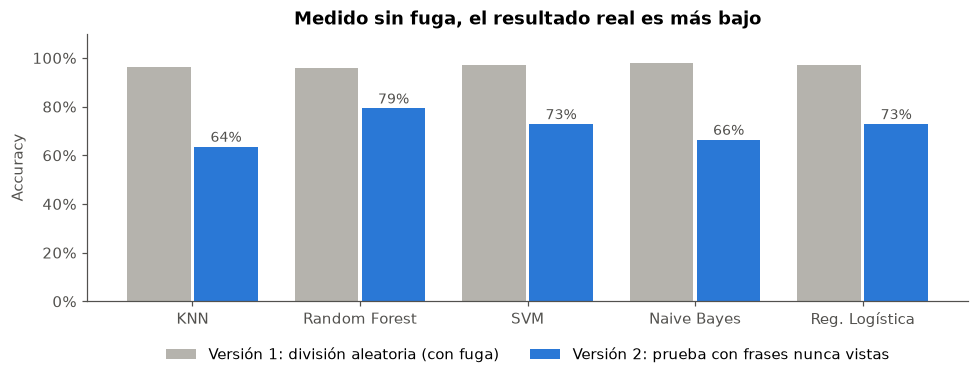

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.6))
pos = np.arange(len(MODELOS))
ax.bar(pos - 0.2, tabla_v1.loc[MODELOS, "Accuracy"], 0.38, color=GRIS, label="Versión 1: división aleatoria (con fuga)")
ax.bar(pos + 0.2, tabla_prueba.loc[MODELOS, "Accuracy"], 0.38, color=AZUL, label="Versión 2: prueba con frases nunca vistas")
for i, n in enumerate(MODELOS):
    ax.text(i + 0.2, tabla_prueba.loc[n, "Accuracy"] + 0.02, f"{tabla_prueba.loc[n, 'Accuracy']:.0%}", ha="center", color=TINTA, fontsize=9)
ax.set_xticks(pos, MODELOS); ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(PORCENTAJE); ax.set_ylabel("Accuracy")
ax.set_title("Medido sin fuga, el resultado real es más bajo")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.show()

**Lectura:** en esta prueba interna Random Forest y SVM quedan arriba y KNN abajo. Antes de concluir revisamos dos cosas: **de dónde sale esa ventaja** y **qué pasa con datos que no vienen de nuestro generador**.

## 3.5 ¿De dónde sale la ventaja de Random Forest?

Repetimos el ajuste (sin tocar la prueba) quitando el monto y la hora, es decir, usando solo **texto y tipo**:

In [17]:
SOLO_TEXTO_Y_TIPO = {"texto": 3.0, "tipo": 1.5, "numero": 0.0, "tiempo": 0.0}
origen = pd.DataFrame({n: {"Todas las variables": f1_ajuste(lambda: crear(n, PESOS_FINALES, **HIPERPARAMETROS[n])),
                           "Solo texto y tipo": f1_ajuste(lambda: crear(n, SOLO_TEXTO_Y_TIPO, **HIPERPARAMETROS[n]))}
                       for n in MODELOS}).T
origen["Cuánto aportan monto y hora"] = origen["Todas las variables"] - origen["Solo texto y tipo"]
origen.style.format("{:.1%}")

,Todas las variables,Solo texto y tipo,Cuánto aportan monto y hora
KNN,51.4%,42.0%,9.4%
Random Forest,69.6%,35.3%,34.3%
SVM,56.3%,49.2%,7.2%
Naive Bayes,48.2%,48.2%,-0.0%
Reg. Logística,55.8%,49.7%,6.1%


**Lectura:** sin monto ni hora, Random Forest cae mucho más que los demás. Su ventaja viene de aprender los **rangos de monto y hora por clase**, y esos rangos los definimos nosotros al construir el dataset sintético. En la vida real un almuerzo y una salida pueden costar lo mismo y ser a la misma hora, así que esa ventaja probablemente no se sostiene. Lo comprobamos con datos externos.

## 3.6 Prueba externa: frases redactadas aparte

`datos/prueba_externa.csv` tiene 70 movimientos (10 por clase) que redactamos **aparte del generador**, con otras palabras, marcas y forma de escribir ("parqueo de la moto", "Bodytech", "plata que me mandó mi mamá") y montos realistas. **Ninguno** se usó para entrenar ni para ajustar. Cada modelo se entrena con los 700 movimientos y se aplica la misma regla de la app (un ingreso solo puede ser *Ingresos* y un gasto nunca lo es).

Si existe `datos/registros_reales.csv` (movimientos reales del equipo, con la plantilla `datos/plantilla_registros_reales.csv`), también se evalúa aquí.

In [18]:
def predecir_como_app(modelo, datos):
    # Igual que la app: un ingreso solo puede ser "Ingresos" y un gasto nunca lo es.
    # (SVM no da probabilidades: se usa su puntaje de decisión para escoger la mayor)
    puntajes = modelo.predict_proba if hasattr(modelo, "predict_proba") else modelo.decision_function
    P = pd.DataFrame(puntajes(datos[COLUMNAS_X]), columns=modelo.classes_, index=datos.index)
    es_ingreso = (datos["tipo_movimiento"] == "Ingreso").to_numpy()
    P.loc[es_ingreso, [c for c in P.columns if c != "Ingresos"]] = -np.inf
    P.loc[~es_ingreso, "Ingresos"] = -np.inf
    return P.idxmax(axis=1).to_numpy(), P.max(axis=1).to_numpy()

def cargar_externo(nombre_archivo):
    try:
        datos = leer(nombre_archivo)
    except Exception:
        print(f"No se encontró {nombre_archivo}"); return None
    datos["fecha_hora"] = pd.to_datetime(datos["fecha_hora"])
    return datos

externa = cargar_externo("prueba_externa.csv")
reales = cargar_externo("registros_reales.csv")

modelos_700 = {n: crear(n, PESOS_FINALES, **HIPERPARAMETROS[n]).fit(X, y) for n in MODELOS}
filas = []
for n in MODELOS:
    fila = {"Modelo": n, "Prueba interna (sec. 3.4)": tabla_prueba.loc[n, "Accuracy"],
            "Prueba externa": accuracy_score(externa.categoria, predecir_como_app(modelos_700[n], externa)[0]),
            "Aprende con 1 corrección (de 36)": aprende_con_una_correccion(lambda: crear(n, PESOS_FINALES, **HIPERPARAMETROS[n]))}
    if reales is not None:
        fila["Registros reales"] = accuracy_score(reales.categoria, predecir_como_app(modelos_700[n], reales)[0])
    filas.append(fila)
comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion.style.format({c: "{:.1%}" for c in comparacion.columns if "corrección" not in c})

No se encontró registros_reales.csv


,Prueba interna (sec. 3.4),Prueba externa,Aprende con 1 corrección (de 36)
Modelo,,,
KNN,63.6%,78.6%,29
Random Forest,79.3%,71.4%,28
SVM,72.9%,77.1%,36
Naive Bayes,66.4%,72.9%,36
Reg. Logística,72.9%,80.0%,36


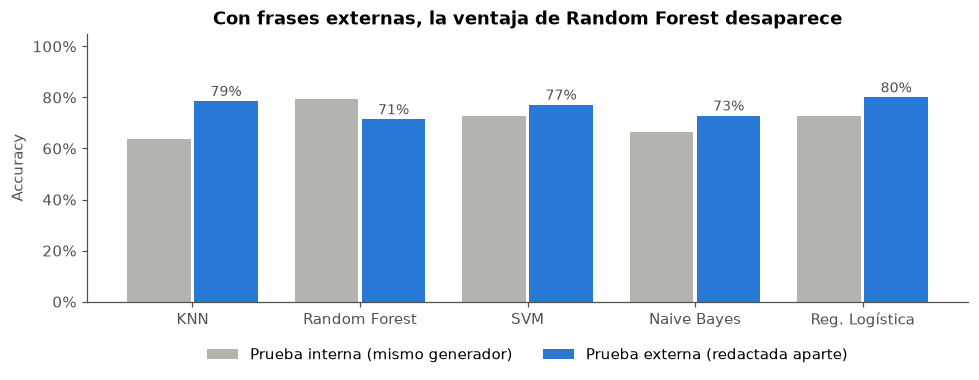

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.6))
pos = np.arange(len(MODELOS))
ax.bar(pos - 0.2, comparacion.loc[MODELOS, "Prueba interna (sec. 3.4)"], 0.38, color=GRIS, label="Prueba interna (mismo generador)")
ax.bar(pos + 0.2, comparacion.loc[MODELOS, "Prueba externa"], 0.38, color=AZUL, label="Prueba externa (redactada aparte)")
for i, n in enumerate(MODELOS):
    ax.text(i + 0.2, comparacion.loc[n, "Prueba externa"] + 0.02, f"{comparacion.loc[n, 'Prueba externa']:.0%}", ha="center", color=TINTA, fontsize=9)
ax.set_xticks(pos, MODELOS); ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(PORCENTAJE); ax.set_ylabel("Accuracy")
ax.set_title("Con frases externas, la ventaja de Random Forest desaparece")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.show()

## 3.7 Decisión: KNN

Resumen honesto de la evidencia:

- **Prueba interna:** Random Forest y SVM son mejores, pero gracias a los rangos de monto y hora que nosotros pusimos en el dataset.
- **Prueba externa:** KNN (79 %) queda a un movimiento de Regresión Logística (80 %) y Random Forest cae al último lugar.
- **Una corrección del usuario:** KNN con K = 5 aprende 29 de 36 (con K = 3 serían las 36) y Random Forest 28.

Como la exactitud no da un ganador claro en todas las pruebas, decidimos por **lo que la app necesita hacer**:

| Necesidad de la app | KNN | Random Forest | SVM / Reg. Logística | Naive Bayes |
|---|---|---|---|---|
| **Explicar** la categoría con ejemplos ("se parece a estos movimientos") | ✅ Los vecinos son la explicación | ❌ Cientos de árboles votando | ❌ Pesos de miles de columnas | ❌ Probabilidades por palabra |
| **Detectar montos inusuales** comparando con movimientos parecidos | ✅ Usa la misma búsqueda de vecinos | ➖ Habría que construirla aparte | ➖ Aparte | ➖ Aparte |
| **Aprender de una corrección** al instante | ✅ Entrenar = guardar el punto | ❌ Reentrenar todo el bosque y aun así falla | ➖ Reentrenar | ✅ Actualizar conteos |
| **Personalizarse** con el historial de cada usuario | ✅ Sus movimientos son los vecinos más cercanos | ➖ Se diluyen | ➖ Se diluyen | ➖ Se diluyen |
| Exactitud en prueba externa | **Alta** | Baja | Alta (Reg. Log.) | Media |

**Modelo elegido: KNN multivariable** con TF-IDF 1-2 gramas, distancia euclidiana ponderada por cercanía y los K y pesos de la sección 3.3.

Si en el futuro tuviéramos miles de registros reales, una opción sería un **modelo híbrido**: Regresión Logística para clasificar y KNN para explicar y detectar inusuales.

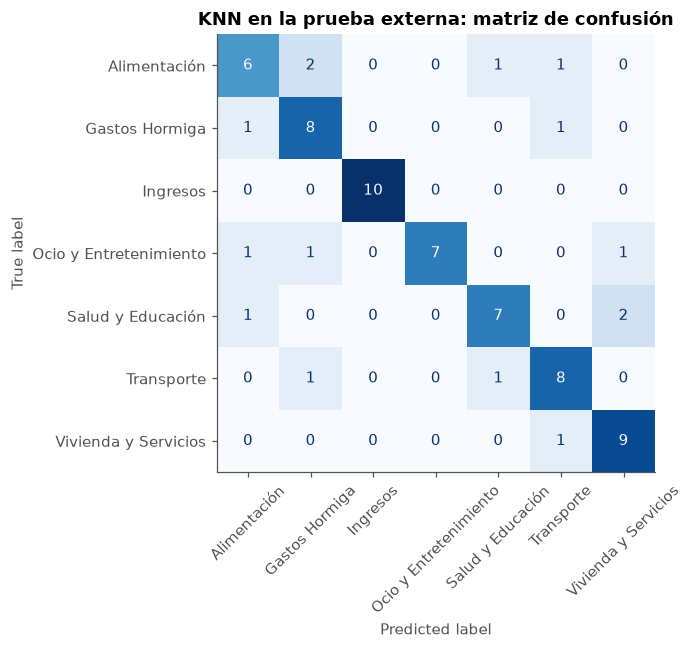

                        precision    recall  f1-score   support

          Alimentación       0.67      0.60      0.63        10
        Gastos Hormiga       0.67      0.80      0.73        10
              Ingresos       1.00      1.00      1.00        10
Ocio y Entretenimiento       1.00      0.70      0.82        10
     Salud y Educación       0.78      0.70      0.74        10
            Transporte       0.73      0.80      0.76        10
  Vivienda y Servicios       0.75      0.90      0.82        10

              accuracy                           0.79        70
             macro avg       0.80      0.79      0.79        70
          weighted avg       0.80      0.79      0.79        70



,descripcion_libre,monto,categoria,prediccion,confianza
0,almuerzo ejecutivo donde la señora de la esquina,"$14,500",Alimentación,Gastos Hormiga,100%
1,mercado de la semana en Justo y Bueno,"$96,000",Alimentación,Salud y Educación,40%
3,compras en el Carulla para la casa,"$58,000",Alimentación,Transporte,100%
8,pan leche y huevos en la tienda del barrio,"$22,000",Alimentación,Gastos Hormiga,60%
11,Uber de vuelta tarde de la noche,"$18,500",Transporte,Salud y Educación,59%
15,taxi a la cita por la mañana,"$15,000",Transporte,Gastos Hormiga,40%
27,detergente y productos de aseo para la casa,"$64,000",Vivienda y Servicios,Transporte,100%
32,discoteca en la 93 el sábado,"$90,000",Ocio y Entretenimiento,Gastos Hormiga,58%
36,boleta para concierto en el Movistar Arena,"$120,000",Ocio y Entretenimiento,Alimentación,60%
39,YouTube Premium mensual,"$17,900",Ocio y Entretenimiento,Vivienda y Servicios,60%


In [20]:
fig, ax = plt.subplots(figsize=(7.5, 6))
pred_ext, conf_ext = predecir_como_app(modelos_700["KNN"], externa)
ConfusionMatrixDisplay.from_predictions(externa.categoria, pred_ext, ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("KNN en la prueba externa: matriz de confusión"); plt.tight_layout(); plt.show()
print(classification_report(externa.categoria, pred_ext, zero_division=0))
externa.assign(prediccion=pred_ext, confianza=conf_ext).loc[lambda d: d.categoria != d.prediccion,
    ["descripcion_libre", "monto", "categoria", "prediccion", "confianza"]].style.format({"confianza": "{:.0%}", "monto": "${:,.0f}"})

Los errores suelen venir de palabras que el modelo nunca vio o que comparte con otra clase ("casa" aparece en "Didi de regreso a la casa", por eso "compras en el Carulla para la casa" se va a Transporte). Por eso en la app el usuario siempre puede corregir, y la siguiente vez el modelo acierta (sección 4.4).

# Parte 4 · Integración del modelo en la app

## 4.1 Modelo final y exportación

El modelo de la app se entrena con los **700** movimientos (ya terminada la evaluación, usar todos los datos es lo correcto) y se guarda como `ia_clasificadora_multivariable_knn.pkl`, con la misma estructura que carga la app. La función `extraer_variables_temporales` también está copiada en `modelo_ia.py`, porque `joblib` guarda el nombre de la función, no su código.

In [21]:
modelo_final = modelos_700["KNN"]
RUTA_PKL = Path("ia_clasificadora_multivariable_knn.pkl")
joblib.dump(modelo_final, RUTA_PKL)
print(f"Guardado {RUTA_PKL} ({RUTA_PKL.stat().st_size / 1024:.0f} KB) con scikit-learn {sklearn.__version__}")
print("Configuración:", modelo_final.named_steps["clasificador"])
print("Pesos por bloque:", modelo_final.named_steps["preprocesador"].transformer_weights)

prueba = pd.DataFrame([
    {"fecha_hora": "2026-11-12 08:10", "monto": 3500, "tipo_movimiento": "Gasto", "descripcion_libre": "tinto y empanada"},
    {"fecha_hora": "2026-11-01 10:00", "monto": 900000, "tipo_movimiento": "Gasto", "descripcion_libre": "pago del arriendo"},
    {"fecha_hora": "2026-11-14 22:30", "monto": 70000, "tipo_movimiento": "Gasto", "descripcion_libre": "salida con amigos al bar"},
    {"fecha_hora": "2026-11-15 09:00", "monto": 1200000, "tipo_movimiento": "Ingreso", "descripcion_libre": "pago de la quincena"},
])
cargado = joblib.load(RUTA_PKL)
prueba.assign(categoria=cargado.predict(prueba), confianza=cargado.predict_proba(prueba).max(1).round(2))

Guardado ia_clasificadora_multivariable_knn.pkl (168 KB) con scikit-learn 1.9.1
Configuración: KNeighborsClassifier(metric='euclidean', weights='distance')
Pesos por bloque: {'texto': 3.0, 'tipo': 1.5, 'numero': 2.0, 'tiempo': 0.5}


,fecha_hora,monto,tipo_movimiento,descripcion_libre,categoria,confianza
0,2026-11-12 08:10,3500,Gasto,tinto y empanada,Gastos Hormiga,1.0
1,2026-11-01 10:00,900000,Gasto,pago del arriendo,Vivienda y Servicios,1.0
2,2026-11-14 22:30,70000,Gasto,salida con amigos al bar,Ocio y Entretenimiento,1.0
3,2026-11-15 09:00,1200000,Ingreso,pago de la quincena,Ingresos,1.0


## 4.2 Cómo lo usa la app

Archivo `modelo_ia.py`, clase `MotorIA`. Cada vez que el usuario registra un movimiento:

```
Usuario escribe descripción, monto, tipo y fecha
        │
        ▼
1. Preprocesador del .pkl → vector (TF-IDF + one-hot + escalados, con sus pesos)
2. KNN busca los vecinos más cercanos entre: 700 de entrenamiento + historial del usuario
3. Votos ponderados por cercanía → categoría + confianza
4. Regla de tipo: un ingreso solo puede ser "Ingresos"; un gasto nunca
5. Si confianza < 60 % o no reconoce ninguna palabra → la app pregunta en vez de decidir
6. Muestra los vecinos como explicación
7. Busca 5 movimientos con descripción parecida y compara montos → ¿inusual?
        │
        ▼
El usuario confirma o corrige → se guarda en SQLite (categoria_ia y categoria_final)
        │
        ▼
analisis.py calcula presupuesto, gastos hormiga y regla 50/30/20 con la categoría final
```

## 4.3 Confianza: ¿cuándo la app pide confirmación?

Medimos qué tan buena es la confianza de KNN para separar aciertos de errores, en la prueba con frases nunca vistas (el caso difícil):

In [22]:
P = modelos_dev["KNN"].predict_proba(X_prueba)
conf = P.max(1); acierto = modelos_dev["KNN"].classes_[P.argmax(1)] == y_prueba.to_numpy()
UMBRAL = 0.60
alta = conf >= UMBRAL
print(f"Confianza >= {UMBRAL:.0%}: {alta.mean():.0%} de los movimientos -> acierta el {acierto[alta].mean():.0%}")
print(f"Confianza <  {UMBRAL:.0%}: {(~alta).mean():.0%} de los movimientos -> acertaría el {acierto[~alta].mean():.0%}, por eso pregunta")
print(f"En la prueba externa, con confianza >= {UMBRAL:.0%} ({(conf_ext >= UMBRAL).mean():.0%} de los casos) acierta el "
      f"{accuracy_score(externa.categoria[conf_ext >= UMBRAL], pred_ext[conf_ext >= UMBRAL]):.0%}")

Confianza >= 60%: 71% de los movimientos -> acierta el 75%
Confianza <  60%: 29% de los movimientos -> acertaría el 37%, por eso pregunta
En la prueba externa, con confianza >= 60% (84% de los casos) acierta el 86%


Cuando KNN está seguro acierta el doble que cuando duda, así que tiene sentido que la app **pregunte** cuando la confianza es baja. Pero con frases nuevas la confianza no basta: KNN puede estar "seguro" y equivocarse. Por eso, aunque la app proponga una categoría, el usuario **siempre** puede cambiarla antes de guardar, y esa corrección es la que hace que el modelo mejore (sección 4.4).

## 4.4 Cómo las correcciones cambian las clasificaciones futuras

1. El usuario **confirma o corrige** la categoría (al registrar o después en Historial). SQLite guarda `categoria_ia` (lo que dijo la IA) y `categoria_final` (lo que decidió el usuario).
2. `MotorIA.aprender()` transforma esos movimientos con el mismo preprocesador y los **agrega como puntos nuevos** del KNN, con la etiqueta `categoria_final`. No hay que reentrenar: en KNN entrenar es guardar puntos.
3. Cuando el usuario escribe algo parecido, su movimiento corregido es el vecino más cercano y, como los votos se ponderan por cercanía, decide.
4. En Historial, la **precisión real** (% de veces que `categoria_ia == categoria_final`) mide el modelo con los datos reales del usuario, sin mezclarlos con el entrenamiento.

Ejemplo concreto con el modelo final:

In [23]:
def explicar(modelo, x, X_ref, y_ref, titulo):
    prob = pd.Series(modelo.predict_proba(x)[0], index=modelo.classes_).sort_values(ascending=False)
    dist, idx = modelo.named_steps["clasificador"].kneighbors(modelo.named_steps["preprocesador"].transform(x))
    print(f"{titulo}: {prob.index[0]} (confianza {prob.iloc[0]:.0%})")
    display(X_ref.iloc[idx[0]][["descripcion_libre", "monto"]].assign(categoria=y_ref.iloc[idx[0]].values,
                                                                      distancia=dist[0].round(2)).reset_index(drop=True))

caso = movimiento("Pago a doña Rosa", 12000, "Gasto", 13)
explicar(modelo_final, caso, X.reset_index(drop=True), y.reset_index(drop=True), "ANTES de corregir")

X_corr = pd.concat([X, caso], ignore_index=True)
y_corr = pd.concat([y, pd.Series(["Alimentación"])], ignore_index=True)   # doña Rosa vende almuerzos
modelo_corr = crear("KNN", PESOS_FINALES, n_neighbors=K_FINAL).fit(X_corr, y_corr)
explicar(modelo_corr, movimiento("pago a doña rosa", 15000, "Gasto", 12, "2026-11-25"), X_corr, y_corr,
         "DESPUÉS de una corrección (otro día, otro monto)")

ANTES de corregir: Vivienda y Servicios (confianza 61%)


,descripcion_libre,monto,categoria,distancia
0,Pago administración conjunto pago rápido,47000,Vivienda y Servicios,3.47
1,pago administración conjunto pago rápido,127000,Vivienda y Servicios,3.56
2,Pago mensualidad Netflix pago rápido,64000,Ocio y Entretenimiento,3.56
3,transferencia pago fijo del mes pago rápido,69000,Vivienda y Servicios,3.65
4,Pago de parqueadero centro comercial pago rápido,6300,Transporte,3.72


DESPUÉS de una corrección (otro día, otro monto): Alimentación (confianza 68%)


,descripcion_libre,monto,categoria,distancia
0,Pago a doña Rosa,12000,Alimentación,0.77
1,Pago administración conjunto pago rápido,47000,Vivienda y Servicios,4.16
2,Pago de parqueadero centro comercial pago rápido,6300,Transporte,4.17
3,desayuno caldo y arepa en panadería pago rápido,17000,Alimentación,4.20
4,compra en droguería turno pago rápido,71500,Salud y Educación,4.21


Y en uso continuo: simulamos a un usuario que registra uno por uno los movimientos de la prueba (frases nuevas). Si la IA se equivoca, el usuario corrige y el movimiento entra al historial. Comparamos el acierto la **primera vez** que aparece una frase con el de las **repeticiones**:

In [24]:
rng = np.random.default_rng(SEMILLA)
X_hist, y_hist = X_dev.copy(), y_dev.copy()
modelo = crear("KNN", PESOS_FINALES, n_neighbors=K_FINAL).fit(X_hist, y_hist)
primera, repeticion, vistas = [], [], set()
for i in rng.permutation(idx_prueba):
    xi, yi, base = X.iloc[[i]], y.iloc[i], grupos.iloc[i]
    ok = modelo.predict(xi)[0] == yi
    (repeticion if base in vistas else primera).append(ok); vistas.add(base)
    X_hist, y_hist = pd.concat([X_hist, xi]), pd.concat([y_hist, y.iloc[[i]]])
    if not ok:
        modelo = crear("KNN", PESOS_FINALES, n_neighbors=K_FINAL).fit(X_hist, y_hist)
print(f"Acierto la primera vez que aparece una frase nueva: {np.mean(primera):.0%} ({len(primera)} casos)")
print(f"Acierto en las repeticiones, después de corregir:  {np.mean(repeticion):.0%} ({len(repeticion)} casos)")

Acierto la primera vez que aparece una frase nueva: 64% (25 casos)
Acierto en las repeticiones, después de corregir:  96% (115 casos)


**Las correcciones sí cambian las clasificaciones futuras:** una frase nueva puede fallar la primera vez, pero después de que el usuario la corrige, las repeticiones casi siempre se aciertan.

*Límite que reconocemos:* la app no reentrena el TF-IDF, así que una palabra totalmente nueva ("Rosa") no entra al vocabulario hasta que reentrenemos el modelo base. Aun así funciona, porque el resto de la frase, el tipo, el monto y la hora llevan al movimiento corregido.

## 4.5 Detección de movimientos inusuales

La app avisa si un monto es **al menos 4 veces mayor** que la mediana de los 5 movimientos parecidos (y al menos $20.000 más), o **20 veces menor** ("¿te faltaron ceros?"). Probamos tres formas de escoger esos "parecidos", en dos escenarios:

- **Frases conocidas:** descripciones que ya tienen hermanas en los datos (el uso diario: "tinto", "Uber a la casa"). Usamos la división aleatoria.
- **Frases nuevas:** la prueba agrupada.

En cada escenario medimos las falsas alarmas (monto normal) y cuántos detecta si el monto se multiplica por 10 o se divide por 100.

In [25]:
def evaluar_inusuales(X_ref, y_ref, X_eval, pesos, minimo_acuerdo=None):
    pre = construir_preprocesador(pesos).fit(X_ref)
    vecinos = NearestNeighbors(n_neighbors=5).fit(pre.transform(X_ref))
    montos, clases = X_ref["monto"].to_numpy(), y_ref.to_numpy()
    def es_inusual(Xq):
        _, idx = vecinos.kneighbors(pre.transform(Xq))
        resultado = []
        for fila, m in zip(idx, Xq["monto"].to_numpy()):
            if minimo_acuerdo is None:
                mediana = np.median(montos[fila])
            else:
                # Solo opina si al menos `minimo_acuerdo` de los 5 parecidos son de la misma clase,
                # y compara contra la mediana de esos
                conteo = pd.Series(clases[fila]).value_counts()
                if conteo.iloc[0] < minimo_acuerdo:
                    resultado.append(False); continue
                mediana = np.median(montos[fila][clases[fila] == conteo.index[0]])
            resultado.append((m / mediana >= 4 and m - mediana >= 20_000) or m / mediana <= 1 / 20)
        return np.array(resultado)
    def con_monto(f):
        Xq = X_eval.copy(); Xq["monto"] = Xq["monto"] * f; return Xq
    return {"Falsas alarmas": es_inusual(X_eval).mean(), "Detecta ×10": es_inusual(con_monto(10)).mean(),
            "Detecta ÷100": es_inusual(con_monto(1 / 100)).mean()}

opciones = {"a) Vecinos de la clasificación (usan el monto)": (PESOS_FINALES, None),
            "b) Vecinos solo por texto y tipo": (SOLO_TEXTO_Y_TIPO, None),
            "c) Texto y tipo + 4 de 5 de acuerdo (versión final)": (SOLO_TEXTO_Y_TIPO, 4)}
filas = []
for nombre, (pesos, acuerdo) in opciones.items():
    conocidas = evaluar_inusuales(X_tr_al, y_tr_al, X_te_al, pesos, acuerdo)
    nuevas = evaluar_inusuales(X_dev, y_dev, X_prueba, pesos, acuerdo)
    filas.append({"Opción": nombre, **{f"Conocidas · {k}": v for k, v in conocidas.items()},
                  **{f"Nuevas · {k}": v for k, v in nuevas.items()}})
pd.DataFrame(filas).set_index("Opción").style.format("{:.0%}")

,Conocidas · Falsas alarmas,Conocidas · Detecta ×10,Conocidas · Detecta ÷100,Nuevas · Falsas alarmas,Nuevas · Detecta ×10,Nuevas · Detecta ÷100
Opción,,,,,,
a) Vecinos de la clasificación (usan el monto),0%,49%,88%,9%,26%,74%
b) Vecinos solo por texto y tipo,2%,90%,100%,20%,83%,86%
c) Texto y tipo + 4 de 5 de acuerdo (versión final),2%,75%,85%,4%,46%,51%


**Lectura:**

- **a)** Si los vecinos se buscan con el monto incluido, quedan con montos parecidos al que se escribió y el monto raro "se esconde": detecta poco.
- **b)** Buscándolos solo por texto y tipo detecta mucho más, pero con frases nuevas los "parecidos" en realidad no se parecen y salen muchas falsas alarmas.
- **c)** La versión final solo juzga el monto cuando **al menos 4 de los 5 parecidos son de la misma clase** (es decir, cuando de verdad sabe con qué comparar) y usa la mediana de esos 4 o 5. Con frases conocidas detecta la mayoría de los montos raros con muy pocas falsas alarmas; con frases nuevas detecta menos, pero casi sin falsas alarmas. Preferimos no molestar al usuario con alertas falsas. Es la versión que quedó en `modelo_ia.py`.

# Parte 5 · Cierre

## Respuestas al feedback de la entrega anterior

| Observación del profesor | Qué hicimos | Dónde |
|---|---|---|
| Especificar que los gastos **se clasifican** mientras el presupuesto **se calcula** | Separamos la tarea de la IA de la de las reglas, con tabla y diagrama | 1.1 y 4.2 |
| Definir las categorías y los **criterios de etiquetado** | 7 clases con su razón de ser y 6 reglas para casos dudosos, verificadas con código | 1.2 |
| Explicar los **datos sintéticos** para ingresos variables | Proceso de construcción en 4 pasos y 16 tipos de ingreso con montos y fechas variables | 2.1 y 2.2 |
| Explicar cómo las **correcciones** cambian las clasificaciones futuras | Mecanismo, ejemplo antes/después y dos experimentos medidos | 3.3 y 4.4 |
| Contrastar con **registros reales**, separando aprendizaje y evaluación | División 70/10/20 agrupada, prueba externa separada, plantilla de registros reales y precisión real en la app | 2.4, 3.6 y 4.4 |
| Mejorar el **manejo del tiempo** | Presentación de 6 diapositivas con guion cronometrado | Presentación |

## Conclusiones

1. Es un problema de **clasificación supervisada multiclase**: `y` = categoría (7 clases); `X` = descripción, tipo, monto y fecha/hora.
2. El texto se convierte en números con **TF-IDF de 1-2 gramas**, que superó claramente a la bolsa de palabras.
3. El 96-98 % de la versión 1 estaba inflado por **fuga de frases**. Con la división 70/10/20 agrupada medimos el resultado real.
4. Ajustamos los hiperparámetros de los 5 modelos con el 10 % de ajuste. En la prueba interna gana Random Forest, pero por regularidades de monto y hora del dataset sintético; en la **prueba externa** KNN y Regresión Logística quedan arriba (79 y 80 %) y Random Forest último.
5. Elegimos **KNN** porque, además de rendir bien con datos externos, es el que permite **explicar con ejemplos, detectar inusuales y aprender al instante** de cada corrección.

## Limitaciones y trabajo futuro

- Dataset sintético con unas 18 frases base por clase: el vocabulario es pequeño. Lo siguiente es reunir **registros reales** de varios usuarios (con su consentimiento) y reentrenar.
- Los montos se generaron por **clase**, no por tipo de movimiento: por eso una "quincena" puede salir de $26.000. Con datos reales esto se corrige.
- La prueba interna tiene 140 filas y la externa 70: diferencias de pocos puntos entre modelos no son concluyentes.
- El TF-IDF no se actualiza con las correcciones; se puede reentrenar cada cierto número de movimientos nuevos.
- En Streamlit Community Cloud la base SQLite se reinicia con cada despliegue; para uso real habría que pasar a una base externa.